In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
df = pd.read_csv('..\W5D1_Dataset_Amazon_UK_Price_Prediction.csv')
print(f"Shape: {df.shape}, Head:\n{df.head()}, Data Types:\n{df.dtypes}")

Shape: (2443651, 9), Head:
   uid        asin                                              title  stars  \
0    1  B09B96TG33  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
1    2  B01HTH3C8S  Anker Soundcore mini, Super-Portable Bluetooth...    4.7   
2    3  B09B8YWXDF  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
3    4  B09B8T5VGV  Echo Dot with clock (5th generation, 2022 rele...    4.7   
4    5  B09WX6QD65  Introducing Echo Pop | Full sound compact Wi-F...    4.6   

   reviews  price  isBestSeller  boughtInLastMonth        category  
0    15308  21.99         False                  0  Hi-Fi Speakers  
1    98099  23.99          True                  0  Hi-Fi Speakers  
2    15308  21.99         False                  0  Hi-Fi Speakers  
3     7205  31.99         False                  0  Hi-Fi Speakers  
4     1881  17.99         False                  0  Hi-Fi Speakers  , Data Types:
uid                    int64
asin                  object
title  

Part 1: Analyzing Best-Seller Trends Across Product Categories

In [4]:
# Create a crosstab between the product `category` and the `isBestSeller` status.
pd.crosstab(df.category, df.isBestSeller)

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [5]:
#Are there categories where being a best-seller is more prevalent? 
# *Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.
df.groupby('category').isBestSeller.mean().sort_values(ascending=False)

category
Grocery                           0.058135
Smart Home Security & Lighting    0.057692
Health & Personal Care            0.057686
Mobile Phone Accessories          0.042471
Power & Hand Tools                0.035339
                                    ...   
Bedding Collections               0.000000
CPUs                              0.000000
CD, Disc & Tape Players           0.000000
Blank Media Cases & Wallets       0.000000
eBook Readers & Accessories       0.000000
Name: isBestSeller, Length: 296, dtype: float64

In [6]:
#conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
pd.crosstab(df.category, df.isBestSeller).apply(lambda x: x / x.sum(), axis=1)

isBestSeller,False,True
category,,
3D Printers,0.995968,0.004032
3D Printing & Scanning,0.999508,0.000492
Abrasive & Finishing Products,0.980000,0.020000
Action Cameras,0.999411,0.000589
Adapters,0.988189,0.011811
...,...,...
Wind Instruments,0.972000,0.028000
Window Treatments,0.979079,0.020921
Women,0.988015,0.011985


In [8]:
# Compute cramer's V test between best-seller status and category
pd.crosstab(df.category, df.isBestSeller).apply(lambda x: x / x.sum(), axis=1).apply(lambda x: x / x.sum(), axis=0)

isBestSeller,False,True
category,,
3D Printers,0.003386,0.002211
3D Printing & Scanning,0.003398,0.000270
Abrasive & Finishing Products,0.003331,0.010967
Action Cameras,0.003397,0.000323
Adapters,0.003359,0.006477
...,...,...
Wind Instruments,0.003304,0.015354
Window Treatments,0.003328,0.011472
Women,0.003359,0.006572


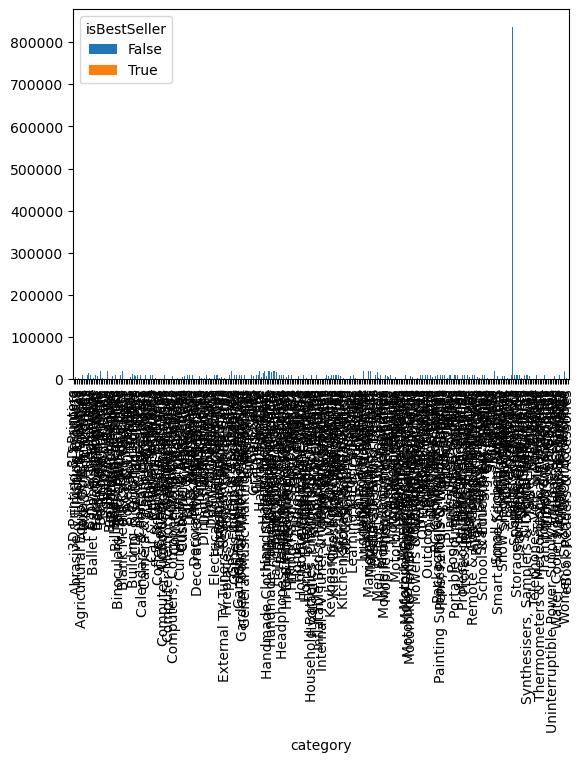

In [9]:
# Visualize the relationship between product categories and the best-seller status using a stacked bar chart
pd.crosstab(df.category, df.isBestSeller).plot(kind='bar', stacked=True)
plt.show()

In [10]:
#For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
df = df[(df.price > df.price.quantile(0.25) - 1.5 * df.price.quantile(0.75)) & (df.price < df.price.quantile(0.75) + 1.5 * df.price.quantile(0.75))]
print(f"Shape: {df.shape}, Head:\n{df.head()}, Data Types:\n{df.dtypes}")

Shape: (2145191, 9), Head:
   uid        asin                                              title  stars  \
0    1  B09B96TG33  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
1    2  B01HTH3C8S  Anker Soundcore mini, Super-Portable Bluetooth...    4.7   
2    3  B09B8YWXDF  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
3    4  B09B8T5VGV  Echo Dot with clock (5th generation, 2022 rele...    4.7   
4    5  B09WX6QD65  Introducing Echo Pop | Full sound compact Wi-F...    4.6   

   reviews  price  isBestSeller  boughtInLastMonth        category  
0    15308  21.99         False                  0  Hi-Fi Speakers  
1    98099  23.99          True                  0  Hi-Fi Speakers  
2    15308  21.99         False                  0  Hi-Fi Speakers  
3     7205  31.99         False                  0  Hi-Fi Speakers  
4     1881  17.99         False                  0  Hi-Fi Speakers  , Data Types:
uid                    int64
asin                  object
title  

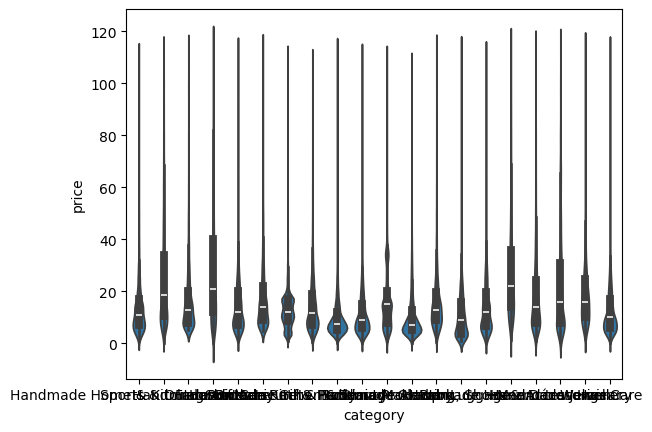

In [12]:
# Use a seaborn violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization
top_20_categories = df.category.value_counts().nlargest(20).index
sns.violinplot(data=df[df.category.isin(top_20_categories)], x='category', y='price')
plt.show()

In [13]:
# Which product category tends to have the highest median price? Don't filter here by top categories.
df.groupby('category').price.median().sort_values(ascending=False)

category
Desktop PCs              78.85
Skiing Poles             76.40
Tablets                  74.55
Motherboards             74.09
Boxing Shoes             69.99
                         ...  
Adapters                  7.05
Make-up                   7.00
Signs & Plaques           6.99
Arts & Crafts             5.99
Office Paper Products     4.37
Name: price, Length: 296, dtype: float64

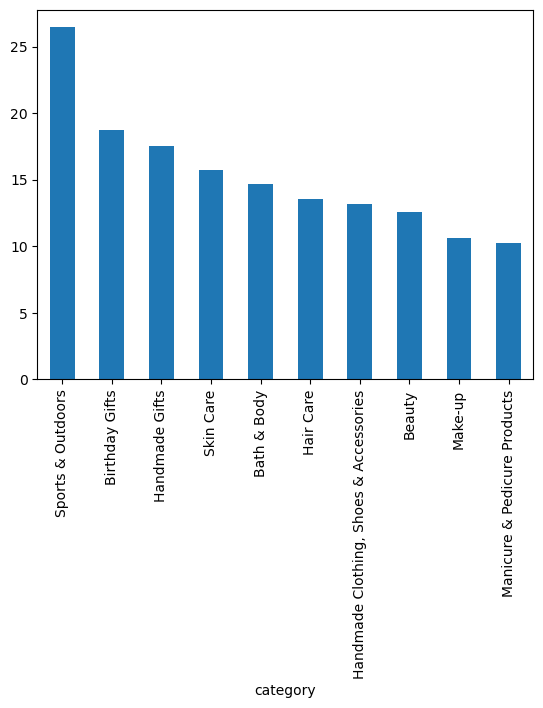

In [14]:
# Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
top_10_categories = df.category.value_counts().nlargest(10).index
df[df.category.isin(top_10_categories)].groupby('category').price.mean().sort_values(ascending=False).plot(kind='bar')
plt.show()

In [15]:
# Which product category commands the highest average price? Don't filter here by top categories.
df.groupby('category').price.mean().sort_values(ascending=False)

category
Motherboards             76.247143
Tablets                  73.397421
Desktop PCs              72.537500
Graphics Cards           69.827812
Boxing Shoes             68.521493
                           ...    
Bedding Accessories       8.835220
Adapters                  8.750197
Signs & Plaques           8.229790
Arts & Crafts             8.006540
Office Paper Products     6.876369
Name: price, Length: 296, dtype: float64

In [16]:
# Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
top_10_categories = df.category.value_counts().nlargest(10).index
sns.boxplot(data=df[df.category.isin(top_10_categories)], x='category', y='ratings')
plt.show()

ValueError: Could not interpret value `ratings` for `y`. An entry with this name does not appear in `data`.

In [18]:
 # Which category tends to receive the highest median rating from customers? Don't filter here by top categories
df.groupby('category').stars.median().sort_values(ascending=False)

category
Computer Memory                                 4.7
Building & Construction Toys                    4.6
Beer, Wine & Spirits                            4.6
Laptop Accessories                              4.6
Hobbies                                         4.6
                                               ... 
Synthesisers, Samplers & Digital Instruments    0.0
Tablets                                         0.0
Action Cameras                                  0.0
3D Printing & Scanning                          0.0
eBook Readers & Accessories                     0.0
Name: stars, Length: 296, dtype: float64

In [ ]:
#  Calculate the correlation coefficient between price and stars for each product category.
df.groupby('category').agg({'price': 'mean', 'stars': 'mean'}).corr()

,price,stars
price,1.000000,-0.378626
stars,-0.378626,1.000000


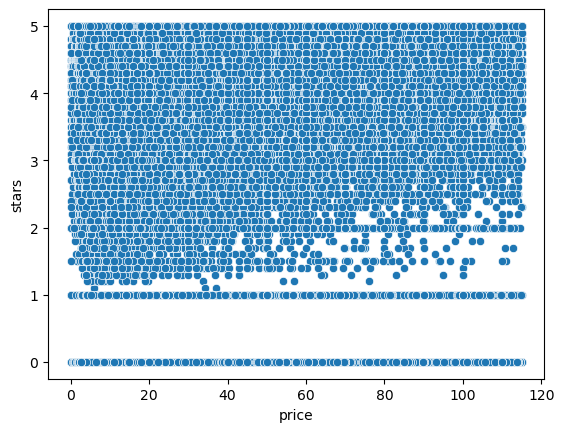

In [21]:
# Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
sns.scatterplot(data=df, x='price', y='stars')
plt.show()

In [22]:
# Use a correlation heatmap to visualize correlations between all numerical variables in the dataset
df.corr()

ValueError: could not convert string to float: 'B09B96TG33'

In [25]:
# Examine if product prices typically follow a normal distribution using a QQ plot
sns.qqplot(df.price)
plt.show()

AttributeError: module 'seaborn' has no attribute 'qqplot'